# CENG313 Assignment 1 – EDA & Baseline

## 1. Problem Definition
* **Task:** In the *Eedi - Mining Misconceptions in Mathematics* competition, each multiple-choice math question has 1 correct answer and 3 incorrect distractor options. Our goal is to predict the specific mathematical misconception behind each incorrect distractor.
* **Target Variable:** MisconceptionId (mapped to text descriptions in misconception_mapping.csv). There are 2,587 unique misconceptions in total.
* **Evaluation Metric:** **MAP@25** (Mean Average Precision at 25). Each model predicts up to 25 ranked misconception IDs for every distractor.

## 2. Data Overview
First, we load the datasets and check their shapes, data types (dtypes), summary statistics (describe()), duplicate rows, and missing value percentages.

In [1]:
from src.data import convert_wide_to_long, get_missing_summary, load_datasets
from src.utils import plot_text_length_distribution, plot_top_categories

train_df, test_df, mapping_df, sub_df = load_datasets(".")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Total misconceptions:", mapping_df.shape[0])
print("Duplicate rows in train_df:", train_df.duplicated().sum())
print("Duplicate rows in mapping_df:", mapping_df.duplicated().sum())

print("\n--- Data Types (train_df) ---")
display(train_df.dtypes.to_frame(name="Data Type"))

print("\n--- Summary Statistics ---")
display(train_df.describe())

print("\n--- Missing Values Summary ---")
display(get_missing_summary(train_df))
display(train_df.head(3))

Train shape: (1869, 15)
Test shape: (3, 11)
Total misconceptions: 2587
Duplicate rows in train_df: 0
Duplicate rows in mapping_df: 0

--- Data Types (train_df) ---


,Data Type
QuestionId,int64
ConstructId,int64
ConstructName,object
SubjectId,int64
SubjectName,object
CorrectAnswer,object
QuestionText,object
AnswerAText,object
AnswerBText,object
AnswerCText,object



--- Summary Statistics ---


,QuestionId,ConstructId,SubjectId,MisconceptionAId,MisconceptionBId,MisconceptionCId,MisconceptionDId
count,1869.000000,1869.000000,1869.000000,1135.000000,1118.000000,1080.000000,1037.000000
mean,934.000000,1613.261637,225.370787,1308.599119,1308.029517,1285.300926,1264.568949
std,539.678145,1060.591804,238.536233,744.518370,766.487351,742.212198,759.818341
min,0.000000,4.000000,33.000000,1.000000,1.000000,2.000000,0.000000
25%,467.000000,575.000000,92.000000,686.000000,628.500000,652.250000,578.000000
50%,934.000000,1470.000000,203.000000,1336.000000,1379.000000,1294.500000,1282.000000
75%,1401.000000,2637.000000,238.000000,1954.000000,1970.000000,1912.000000,1897.000000
max,1868.000000,3526.000000,1984.000000,2585.000000,2586.000000,2585.000000,2583.000000



--- Missing Values Summary ---


,Missing Count,Missing Percentage (%)
MisconceptionDId,832,44.52
MisconceptionCId,789,42.22
MisconceptionBId,751,40.18
MisconceptionAId,734,39.27


,QuestionId,ConstructId,ConstructName,SubjectId,SubjectName,CorrectAnswer,QuestionText,AnswerAText,AnswerBText,AnswerCText,AnswerDText,MisconceptionAId,MisconceptionBId,MisconceptionCId,MisconceptionDId
0,0,856,Use the order of operations to carry out calcu...,33,BIDMAS,A,\[\n3 \times 2+4-5\n\]\nWhere do the brackets ...,\( 3 \times(2+4)-5 \),\( 3 \times 2+(4-5) \),\( 3 \times(2+4-5) \),Does not need brackets,NaN,NaN,NaN,1672.0
1,1,1612,Simplify an algebraic fraction by factorising ...,1077,Simplifying Algebraic Fractions,D,"Simplify the following, if possible: \( \frac{...",\( m+1 \),\( m+2 \),\( m-1 \),Does not simplify,2142.0,143.0,2142.0,NaN
2,2,2774,Calculate the range from a list of data,339,Range and Interquartile Range from a List of Data,B,Tom and Katie are discussing the \( 5 \) plant...,Only\nTom,Only\nKatie,Both Tom and Katie,Neither is correct,1287.0,NaN,1287.0,1073.0


**Data Overview Notes:**
* train.csv has 1,869 questions and 15 columns, with **0 duplicate rows**.
* The misconception columns (MisconceptionAId to MisconceptionDId) have around **39% to 44% missing values**. This happens because one option in every question is the correct answer (so it has no misconception), and some wrong options were not labeled in the raw dataset.


## 3. Preprocessing
* **Why Wide-to-Long Conversion?** In the original train.csv, all 4 choices (A, B, C, D) are in a single row. However, the target is defined per incorrect choice (QuestionId_Answer, such as 0_D or 1_A). We convert the table from wide to long format and remove the correct answer choices, which gives us 1,869 * 3 = 5,607 distractor rows.
* **Why Drop Missing Targets?** Out of 5,607 distractors, 1,237 do not have a MisconceptionId label (NaN). Since we cannot train or evaluate on unlabeled targets, we drop the missing rows and keep the **4,370 valid labeled distractors** for our analysis and validation split.

In [2]:
train_long = convert_wide_to_long(train_df, is_train=True)
test_long = convert_wide_to_long(test_df, is_train=False)

train_valid = train_long.dropna(subset=["MisconceptionId"]).copy()
train_valid["MisconceptionId"] = train_valid["MisconceptionId"].astype(int)

print("Total distractors:", len(train_long))
print("Valid labeled distractors:", len(train_valid))

display(train_valid[["QuestionId_Answer", "SubjectName", "DistractorText", "MisconceptionId"]].head(3))

Total distractors: 5607
Valid labeled distractors: 4370


,QuestionId_Answer,SubjectName,DistractorText,MisconceptionId
2,0_D,BIDMAS,Does not need brackets,1672
3,1_A,Simplifying Algebraic Fractions,\( m+1 \),2142
4,1_B,Simplifying Algebraic Fractions,\( m+2 \),143


## 4. Exploratory Data Analysis (EDA)
Below we plot the top 15 math subjects, top 15 constructs, question word count distribution, and top 15 most frequent misconceptions.

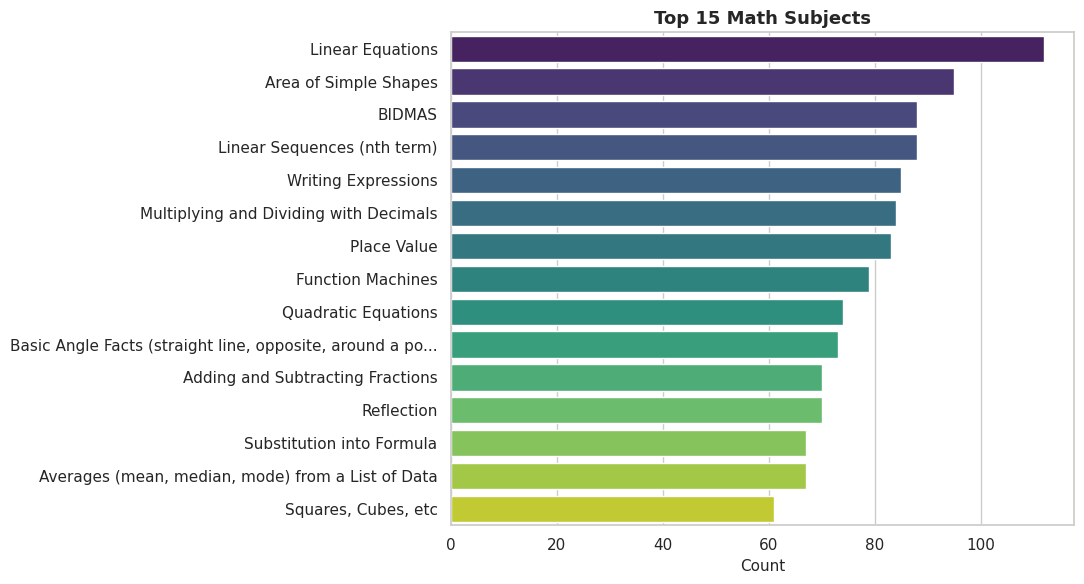

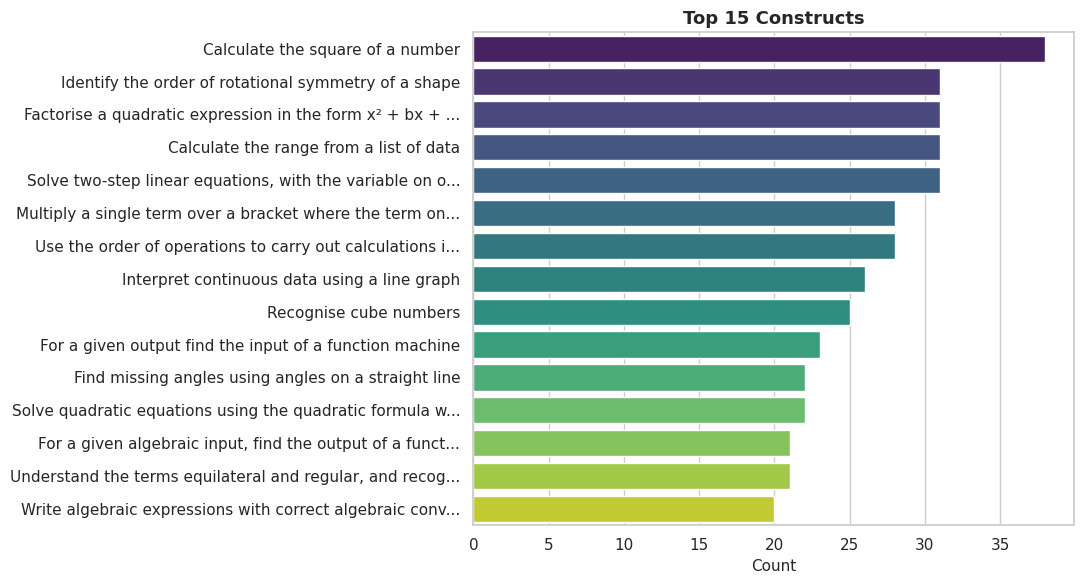

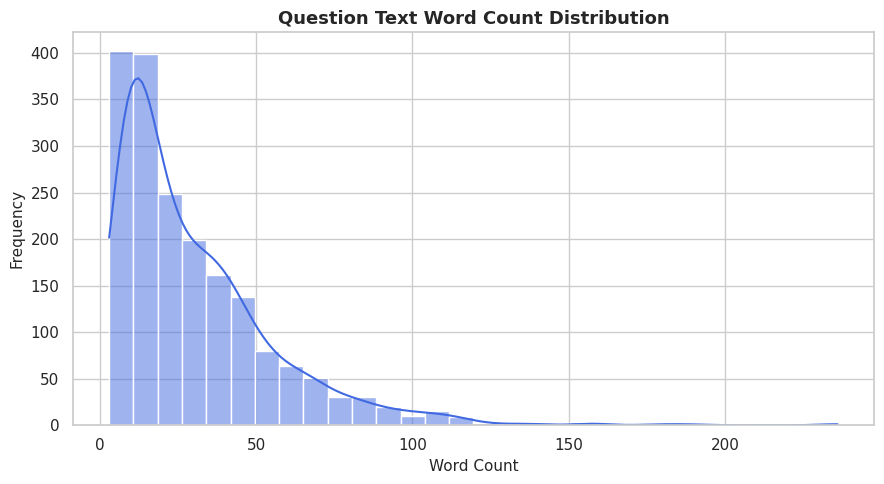

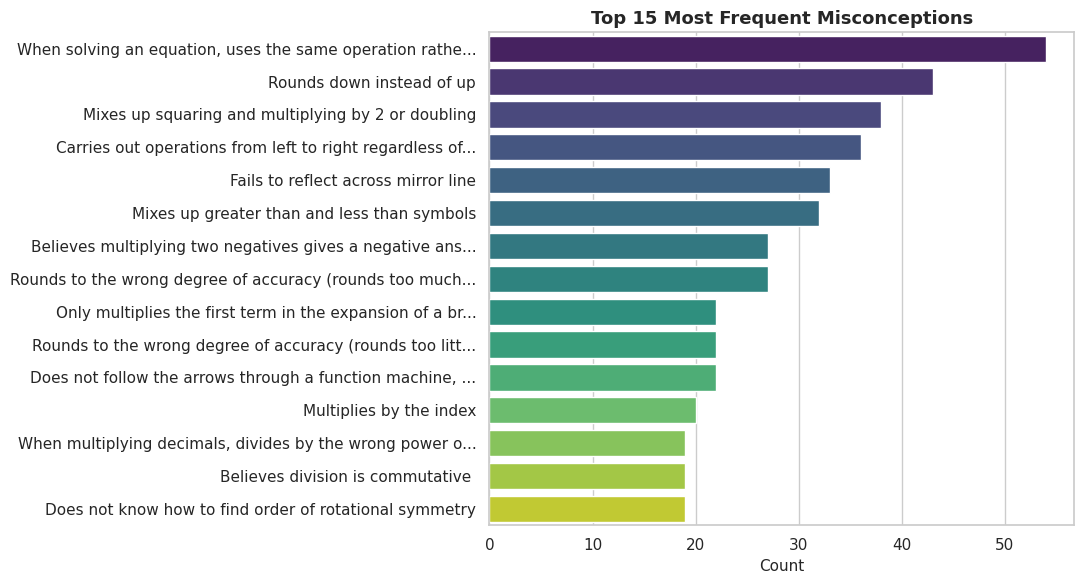

In [3]:
import importlib
import src.utils
importlib.reload(src.utils)
from src.utils import plot_top_categories, plot_text_length_distribution

plot_top_categories(
    train_valid,
    column="SubjectName",
    top_n=15,
    title="Top 15 Math Subjects",
    xlabel="Count"
)

plot_top_categories(
    train_valid,
    column="ConstructName",
    top_n=15,
    title="Top 15 Constructs",
    xlabel="Count"
)

plot_text_length_distribution(
    train_df,
    column="QuestionText",
    title="Question Text Word Count Distribution"
)

train_with_names = train_valid.merge(mapping_df, on="MisconceptionId", how="left")
plot_top_categories(
    train_with_names,
    column="MisconceptionName",
    top_n=15,
    title="Top 15 Most Frequent Misconceptions",
    xlabel="Count"
)

###Interpretation of EDA Plots

1. **Top 15 Math Subjects**
The most common subjects in the dataset are Linear Equations (over 100 distractors), Area of Simple Shapes, BIDMAS, and Linear Sequences. This shows that algebra and basic geometry make up a large portion of the diagnostic questions.
2. **Top 15 Constructs**
Looking at specific mathematical skills (ConstructName), topics like "Calculate the square of a number" (38 times) and "Identify the order of rotational symmetry" are the most frequent. Many questions test the exact same construct.
3. **Question Text Word Count Distribution (Outliers)**
Most questions are short and contain between 10 and 45 words, making the distribution right-skewed. However, there are a few outliers reaching 150 to 230+ words, which represent long story-based math problems.
4. **Top 15 Most Frequent Misconceptions (Target Balance)**
The target variable is highly imbalanced. Out of 2,587 misconceptions, the most common one ("When solving an equation, uses the same operation rather than the inverse") appears more than 50 times, while many others appear only once or twice. Because there are so many rare classes, standard classification is difficult. Instead, a text similarity approach (comparing question and distractor text with misconception descriptions) is much more effective.


##5. Baseline Models & Validation Split

Since the competition is closed, we use an 80% - 20% train/validation split (random_state=42, 874 validation samples) and evaluate three baseline models from src/models.py using MAP@25:

• **Most Frequent (Top 25):** Predicts the 25 most common misconceptions from the training split for every question.

• **CountVectorizer + Cosine Similarity:** Combines SubjectName, ConstructName, QuestionText, and DistractorText, converts them into word count vectors, and ranks misconceptions by cosine similarity.

• **TF-IDF + Cosine Similarity:** Uses TF-IDF vectors (1-gram and 2-gram) with cosine similarity to give higher weight to specific math terms.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from src.models import MostFrequentBaseline, TextSimilarityBaseline
from src.utils import mapk

# 1. Eğitim ve doğrulama setlerine ayırır (%80 - %20)
train_split, val_split = train_test_split(
    train_valid, test_size=0.20, random_state=42
)

actual_targets = val_split["MisconceptionId"].tolist()

# 2. Most Frequent Baseline
freq_model = MostFrequentBaseline(k=25)
freq_model.fit(train_split)
freq_preds = freq_model.predict(val_split)
freq_score = mapk(actual_targets, freq_preds, k=25)

# 3. CountVectorizer Baseline
count_model = TextSimilarityBaseline(method="count", k=25)
count_model.fit(mapping_df)
count_preds = count_model.predict(val_split)
count_score = mapk(actual_targets, count_preds, k=25)

# 4. TF-IDF Baseline
tfidf_model = TextSimilarityBaseline(method="tfidf", k=25)
tfidf_model.fit(mapping_df)
tfidf_preds = tfidf_model.predict(val_split)
tfidf_score = mapk(actual_targets, tfidf_preds, k=25)

# Sonuçları tablo olarak yazdır
results_df = pd.DataFrame({
    "Baseline Model": [
        "Most Frequent (Top 25)",
        "CountVectorizer + Cosine Similarity",
        "TF-IDF + Cosine Similarity",
    ],
    "Validation MAP@25": [
        round(freq_score, 4),
        round(count_score, 4),
        round(tfidf_score, 4),
    ],
})

print("Validation Set Size:", len(val_split))
display(results_df)

Validation Set Size: 874


,Baseline Model,Validation MAP@25
0,Most Frequent (Top 25),0.0363
1,CountVectorizer + Cosine Similarity,0.1292
2,TF-IDF + Cosine Similarity,0.1389



##6. Comparison with Kaggle Public Scores

• On our 20% held-out validation set, the Most Frequent baseline gets 0.0363, CountVectorizer gets 0.1292, and TF-IDF gets 0.1389 MAP@25.

• **Leaderboard Comparison:** On the Kaggle public leaderboard, top solutions using large language models (LLMs) reach scores around 0.45 – 0.65+, while basic text baselines score around 0.10 – 0.15. Our TF-IDF baseline (0.1389) is in line with simple public baselines, though still far from top scores since TF-IDF only matches exact words and cannot capture mathematical meaning.

##7. Conclusion & Next Steps

• **Key Findings:** Using text similarity (CountVectorizer and TF-IDF) improves the MAP@25 score from 0.0363 to 0.1389 (almost 4x better than guessing the most frequent labels). Combining subject, construct, question, and distractor text provides useful keyword overlap with misconception names.

• **Next Steps (Assignment 2):** In Assignment 2, we plan to use pre-trained Sentence Transformer embeddings (Bi-Encoders) instead of simple word counts so the model can capture semantic similarity. We will also include the CorrectAnswer text to better understand the mistake in each distractor.
